# 07 · Wilayah asal berbeda, tujuan kunjungan siangnya juga berbeda

Desember 2021–Februari 2022 · Kota Yogyakarta · WIB

## Ringkasan

Banguntapan paling banyak teramati di Umbulharjo, sedangkan Depok di Gondokusuman,
di antara tujuan dalam Kota yang dipublikasikan. Tujuan teratas masing-masing asal
itu sama pada ketiga bulan. Ini menunjukkan perbedaan pola keterhubungan wilayah
dalam sampel, yang dapat menjadi dasar memilih pasangan wilayah untuk observasi lanjutan.

Ringkasan berbobot tiga bulan: Banguntapan tercatat di Umbulharjo **20,5%** dan
Gondokusuman **7,3%**; Depok di Umbulharjo **5,3%** dan Gondokusuman **10,0%**.
Persentase memakai perangkat dengan rumah bulanan di masing-masing asal sebagai
pembagi. Angka ini bukan persentase penduduk dan bukan jumlah perjalanan.

Pertanyaan utama: **apakah dua asal dengan hubungan kunjungan terbesar mempunyai
pola tujuan yang sama, dan apakah perbedaannya terlihat setiap bulan?**

Baca sampai bagian kesimpulan untuk cerita utama. Grafik volume, perbandingan
tambahan, dan pemeriksaan teknis disimpan di lampiran.

## Konteks dan cara membaca

Perbandingan JogjaPulse dan Google pada output 1 menunjukkan bahwa kedua sumber
menangkap aspek mobilitas yang berbeda. Analisis ini memakai rincian asal–tujuan
JogjaPulse untuk melihat hubungan wilayah yang tidak tersedia pada Google tingkat
provinsi. Hasil ini tidak diturunkan dari nilai korelasi kedua sumber.

“Kunjungan siang” berarti perangkat dengan estimasi rumah di satu kapanewon
teramati setidaknya sekali di tujuan pada **08.00–17.59 WIB** dalam bulan yang sama.
Perangkat yang tercatat sekali maupun setiap hari sama-sama dihitung satu kali
pada pasangan asal–tujuan–bulan tersebut. Rumah bulanan diperkirakan dari lokasi
malam dengan sekurangnya dua malam teramati.

Proporsi bulanan = perangkat asal yang tercatat di tujuan / semua perangkat
dengan rumah bulanan di asal. Ringkasan tiga bulan = jumlah pembilang bulanan /
jumlah pembagi bulanan. Perangkat dapat berulang antarbulan; hasilnya merupakan
proporsi berbobot perangkat-bulan, bukan perangkat unik selama tiga bulan.

### Asumsi yang memengaruhi hasil

- Cakupan: asal di luar Kota Yogyakarta dan tujuan individual di dalam Kota.
  Maret–April dikeluarkan karena kualitas OD ditandai rendah oleh sumber.
- Pasangan lengkap ketiga bulan dipakai untuk memilih hubungan terbesar menurut
  rata-rata jumlah perangkat bulanan. Dua hubungan teratas dipakai sebagai fokus,
  lalu kedua asal dibandingkan pada kedua tujuan yang sama. Pemilihan ini
  eksploratif; tidak mewakili semua asal di DIY.
- Data tidak terbit tetap tidak diketahui, bukan nol. Sampel ponsel berubah dan
  bukan sampel acak penduduk. Normalisasi tidak menghilangkan seluruh biasnya.
- Satu perangkat dapat muncul pada lebih dari satu tujuan. Persentase ini bukan
  pembagian pilihan yang saling terpisah, dan tidak dijumlah menjadi pengunjung Kota unik.

Sumber: [JogjaPulse v1](https://zenodo.org/records/23157460), khususnya
`od_home_visits_kapanewon_monthly.csv`, `od_origin_homes_monthly.csv`, dan README
sumber bagian 4.6–4.7, 5–6. Pipeline repo menyediakan
`data/processed/od_dec_feb.parquet`, `data/interim/od_homes.parquet`, dan
`data/interim/kapanewon_crosswalk.csv`. Kode wilayah menjadi kunci penggabungan.
Hash input tercatat pada `data/processed/daytime_visits/quality.json`.

## Data dan perhitungan

Jalankan pipeline pada README sebelum notebook. Sel berikut membentuk tabel
pasangan dan menetapkan gaya grafik. Hasil disimpan di `reports/`.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'config.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Jalankan notebook dari root repo atau folder notebooks/.')
sys.path.insert(0, str(ROOT / 'src'))
from analyze_daytime_visits import run_analysis
from config import FIGURES, OD_GOOD_MONTHS

pair_month, pairs, quality = run_analysis()
complete = pairs[pairs.complete_months].copy()
TOP_K = 10
DESTINATION_CODE = '34.71.13'  # Umbulharjo; ubah untuk menelusuri tujuan lain
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13})
COLORS = ['#0F766E', '#C2410C', '#2563EB']
MONTH_LABELS = ['Des 2021', 'Jan 2022', 'Feb 2022']
def save(fig, name):
    fig.savefig(FIGURES / f'rq4_{name}.png', bbox_inches='tight', facecolor='white')

### Pilih fokus dari hubungan terbesar, lalu periksa ke file sumber

Pemilihan berasal dari ranking seluruh pasangan lengkap, bukan dari mencari
perbedaan persentase terbesar. Tabel di bawah menunjukkan dua hubungan pertama;
empat kombinasi kedua asal dan tujuan diperiksa terhadap CSV mentah yang sama.

In [2]:
leaders = complete.head(2).copy()
origin_codes = leaders.origin_code.tolist()
dest_codes = leaders.dest_code.tolist()
assert len(set(origin_codes)) == len(set(dest_codes)) == 2
focus = pair_month.loc[pair_month.origin_code.isin(origin_codes)
                       & pair_month.dest_code.isin(dest_codes)].copy()
assert len(focus) == 4 * len(OD_GOOD_MONTHS) and focus.published.all()
focus_summary = complete.loc[complete.origin_code.isin(origin_codes)
                             & complete.dest_code.isin(dest_codes)].copy()
assert len(focus_summary) == 4

raw_visits = pd.read_csv(ROOT / 'data/raw/jogjapulse/od_home_visits_kapanewon_monthly.csv',
                         dtype={'origin_code': str, 'dest_code': str, 'month': str})
raw_homes = pd.read_csv(ROOT / 'data/raw/jogjapulse/od_origin_homes_monthly.csv',
                        dtype={'origin_code': str, 'month': str})
keys = ['month', 'origin_code', 'dest_code']
check = focus.merge(raw_visits[keys + ['n_maids', 'reduced_quality']],
                     on=keys, validate='one_to_one', suffixes=('', '_raw'))
check = check.merge(raw_homes[['month', 'origin_code', 'n_homed_maids']],
                     on=['month', 'origin_code'], validate='many_to_one', suffixes=('', '_raw'))
assert len(check) == len(focus)
assert check.n_maids.eq(check.n_maids_raw).all()
assert check.n_homed_maids.eq(check.n_homed_maids_raw).all()
assert not check.reduced_quality.any()
for row in focus_summary.itertuples():
    part = check.loc[check.origin_code.eq(row.origin_code) & check.dest_code.eq(row.dest_code)]
    assert np.isclose(part.n_maids_raw.sum() / part.n_homed_maids_raw.sum(), row.pooled_visit_rate)

all_destinations = pair_month.loc[pair_month.origin_code.isin(origin_codes)].copy()
all_destinations['destination_rank_in_origin_month'] = all_destinations.groupby(
    ['month', 'origin_code']).n_maids.rank(method='min', ascending=False)
evidence = focus.merge(all_destinations[keys + ['destination_rank_in_origin_month']],
                        on=keys, validate='one_to_one')
evidence.to_csv(ROOT / 'reports/tables/rq4_daytime_story_evidence.csv', index=False)
display(leaders[['pair_label', 'mean_devices_per_month']].rename(columns={
    'pair_label': 'Hubungan fokus', 'mean_devices_per_month': 'Rata-rata perangkat/bulan'
}).style.format({'Rata-rata perangkat/bulan': '{:,.1f}'}))

,Hubungan fokus,Rata-rata perangkat/bulan
0,Banguntapan (Bantul) → Umbulharjo,"1,092.7"
1,Depok (Sleman) → Gondokusuman,837.3


## Hasil utama

### 1. Dua asal memperlihatkan pola tujuan yang berbeda

Tujuan yang sama dibandingkan untuk kedua asal. Proporsi terhadap sampel asal
membantu membaca keterhubungan tanpa hanya mengikuti banyaknya perangkat yang
tersedia dari setiap asal. Pembagi tetap berbeda antarasal.

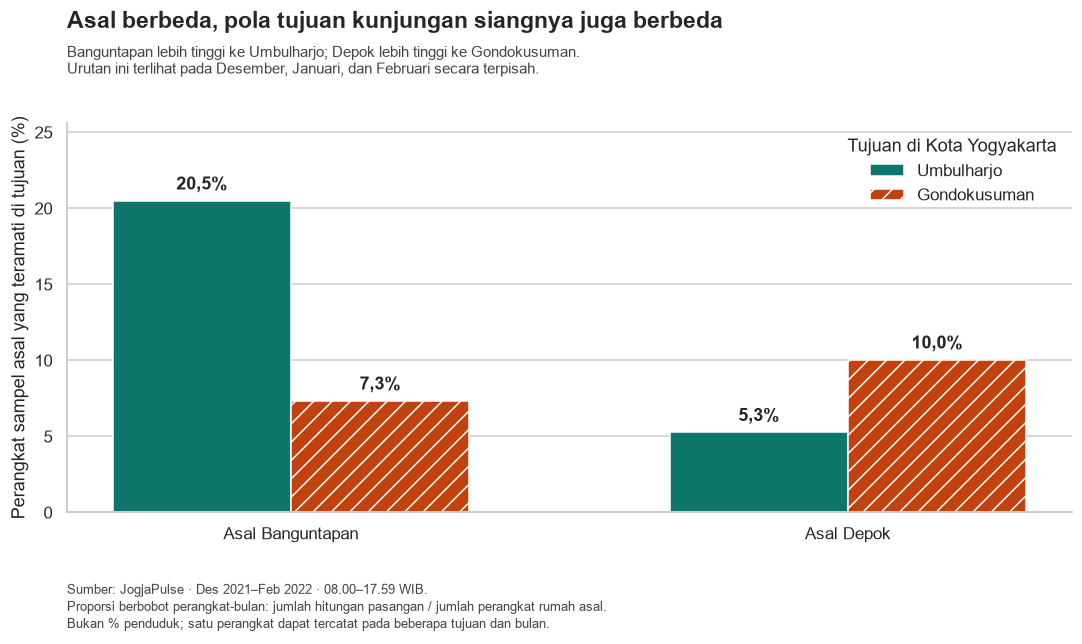

In [3]:
origin_labels = [leaders.loc[leaders.origin_code.eq(o), 'origin_kapanewon'].iloc[0].title()
                 for o in origin_codes]
destination_labels = [leaders.loc[leaders.dest_code.eq(d), 'dest_kapanewon'].iloc[0].title()
                      for d in dest_codes]
pooled_rates = focus_summary.pivot(index='origin_code', columns='dest_code',
                                   values='pooled_visit_rate').reindex(index=origin_codes, columns=dest_codes)
fig, ax = plt.subplots(figsize=(10.5, 6))
positions = np.arange(len(origin_codes))
width = .32
for i, (d, label, color, hatch) in enumerate(zip(dest_codes, destination_labels, COLORS, ['', '//'])):
    values = pooled_rates[d].astype(float).to_numpy() * 100
    bars = ax.bar(positions + (i - .5) * width, values, width, label=label,
                  color=color, hatch=hatch, edgecolor='white')
    ax.bar_label(bars, labels=[f'{v:.1f}%'.replace('.', ',') for v in values],
                 padding=5, fontsize=12, weight='bold')
ax.set_xticks(positions, ['Asal ' + s for s in origin_labels])
ax.set_ylabel('Perangkat sampel asal yang teramati di tujuan (%)')
ax.set_ylim(0, float(pooled_rates.max().max()) * 100 * 1.25)
ax.grid(axis='x', visible=False)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(title='Tujuan di Kota Yogyakarta', loc='upper right', frameon=False)
fig.suptitle('Asal berbeda, pola tujuan kunjungan siangnya juga berbeda',
             x=.1, ha='left', fontsize=15, weight='bold', y=.97)
fig.text(.1, .875, 'Banguntapan lebih tinggi ke Umbulharjo; Depok lebih tinggi ke Gondokusuman.\n'
         'Urutan ini terlihat pada Desember, Januari, dan Februari secara terpisah.',
         fontsize=10, color='#444444')
fig.text(.1, .035, 'Sumber: JogjaPulse · Des 2021–Feb 2022 · 08.00–17.59 WIB.\n'
         'Proporsi berbobot perangkat-bulan: jumlah hitungan pasangan / jumlah perangkat rumah asal.\n'
         'Bukan % penduduk; satu perangkat dapat tercatat pada beberapa tujuan dan bulan.',
         fontsize=8.5, color='#444444', linespacing=1.4)
fig.subplots_adjust(top=.80, bottom=.21, left=.1, right=.97)
save(fig, 'destination_pattern')
plt.show()

Banguntapan tercatat lebih tinggi di Umbulharjo (20,5%) daripada Gondokusuman
(7,3%). Untuk Depok, urutannya berbalik: Gondokusuman 10,0%, Umbulharjo 5,3%.
Artinya, pola hubungan siang menuju Kota berbeda menurut wilayah asal.
Ini tidak berarti perangkat hanya memilih salah satu dari kedua tujuan.

### 2. Perbedaannya terlihat setiap bulan

Pemeriksaan berikut memisahkan Desember, Januari, dan Februari agar ringkasan
tiga bulan tidak menutupi perubahan urutan. Yang konsisten adalah urutan
tujuan, bukan besarnya persentase maupun identitas perangkat yang berkunjung.

In [4]:
monthly = evidence.pivot(index=['origin_code', 'dest_code'], columns='month', values='visit_rate')
monthly = monthly.reindex(index=pd.MultiIndex.from_product([origin_codes, dest_codes]), columns=OD_GOOD_MONTHS)
monthly.index = [focus_summary.loc[focus_summary.origin_code.eq(o) & focus_summary.dest_code.eq(d),
                                  'pair_label'].iloc[0] for o, d in monthly.index]
monthly.index.name = 'Asal dan tujuan'
monthly.columns = MONTH_LABELS
display(monthly.style.format(lambda v: f'{v:.1%}'.replace('.', ',')))

for row in leaders.itertuples():
    selected_destination = evidence.loc[evidence.origin_code.eq(row.origin_code)
                                         & evidence.dest_code.eq(row.dest_code)]
    assert selected_destination.destination_rank_in_origin_month.eq(1).all()
for o in origin_codes:
    rates = evidence.loc[evidence.origin_code.eq(o)].pivot(index='month', columns='dest_code', values='visit_rate')
    preferred = leaders.loc[leaders.origin_code.eq(o), 'dest_code'].iloc[0]
    other = next(d for d in dest_codes if d != preferred)
    assert rates[preferred].gt(rates[other]).all()

,Des 2021,Jan 2022,Feb 2022
Asal dan tujuan,,,
Banguntapan (Bantul) → Umbulharjo,"20,3%","23,5%","17,1%"
Banguntapan (Bantul) → Gondokusuman,"5,4%","8,0%","9,6%"
Depok (Sleman) → Umbulharjo,"4,9%","5,4%","5,6%"
Depok (Sleman) → Gondokusuman,"8,2%","10,7%","11,7%"


Umbulharjo merupakan tujuan Kota teratas yang dipublikasikan untuk asal
Banguntapan pada setiap bulan; Gondokusuman juga teratas untuk Depok.
Jadi pola tersebut tidak hanya muncul dari penggabungan tiga bulan.
Tiga bulan belum membuktikan kebiasaan jangka panjang: ukuran dan komposisi
sampel berubah, dan perangkat yang sama tidak dapat dilacak dari agregat ini.

## Kesimpulan dan kegunaannya

Temuan: sampel dari dua wilayah asal memperlihatkan keterhubungan siang yang
berbeda dengan tujuan dalam Kota, dan urutan tujuan utamanya bertahan selama
Desember–Februari. Membaca Kota hanya sebagai satu tujuan akan menyembunyikan
perbedaan ini.

Hipotesis: perbedaan fungsi kawasan, akses, atau kegiatan rutin seperti bekerja
dan belajar mungkin berkaitan dengan pola tersebut. Dataset ini belum
menguji faktor-faktor itu dan tidak memuat tujuan perjalanan atau moda.

Kegunaan aplikatifnya adalah memilih Banguntapan–Umbulharjo dan
Depok–Gondokusuman sebagai pasangan awal untuk observasi atau survei
keterhubungan siang. Data memberi arah untuk ditelusuri; kebutuhan rute dan
kapasitas angkutan memerlukan bukti tambahan.

Kalimat yang dapat diceritakan: “Ketika kita melihat rincian asal dan tujuan,
hubungan siang ke Kota ternyata berbeda menurut asal. Banguntapan paling
banyak teramati di Umbulharjo, sedangkan Depok di Gondokusuman. Tujuan teratas
itu sama pada ketiga bulan. Kita dapat memakai pola ini untuk memilih hubungan
wilayah yang perlu diamati lebih lanjut; alasan bekerja, belajar, atau akses
masih merupakan hipotesis.”

## Lampiran: bukti dan penelusuran tambahan

Bagian ini mendukung pemeriksaan hasil dan tidak perlu menjadi materi utama
video. Tabel bukti utama berada di `reports/tables/rq4_daytime_story_evidence.csv`.

### Cakupan publikasi

Cakupan memakai 64 asal × 14 tujuan × 3 bulan. Pasangan tidak terbit tidak
direkonstruksi; cakupan pasangan tidak sama dengan proporsi kunjungan yang pulih.

In [5]:
qa_table = pd.DataFrame([
    ['Kemungkinan pasangan-bulan', quality['possible_pair_months']],
    ['Pasangan-bulan terbit', quality['published_pair_months']],
    ['Pasangan-bulan tidak terbit', quality['unpublished_pair_months']],
    ['Kemungkinan pasangan asal–tujuan', quality['possible_pairs']],
    ['Pasangan terbit ketiga bulan', quality['complete_three_month_pairs']],
    ['Baris antarwilayah bernama sama yang tetap dipertahankan', quality['name_collision_pairs_retained']],
], columns=['Pemeriksaan', 'Hasil'])
display(qa_table)
assert not pair_month.duplicated(['month', 'origin_code', 'dest_code']).any()
assert pair_month.loc[~pair_month.published, 'n_maids'].isna().all()
assert pair_month.loc[pair_month.published, 'visit_rate'].between(0, 1).all()

,Pemeriksaan,Hasil
0,Kemungkinan pasangan-bulan,2688
1,Pasangan-bulan terbit,1361
2,Pasangan-bulan tidak terbit,1327
3,Kemungkinan pasangan asal–tujuan,896
4,Pasangan terbit ketiga bulan,329
5,Baris antarwilayah bernama sama yang tetap dip...,3


### Seluruh hubungan besar sebagai konteks pemilihan fokus

Ranking rata-rata hanya menggunakan pasangan terbit ketiga bulan. Grafik ini
menjelaskan mengapa Banguntapan–Umbulharjo dan Depok–Gondokusuman dipilih.

,Pasangan,Bulan terbit,Mean MAID/bulan,Rate berbobot 3 bulan
0,Banguntapan (Bantul) → Umbulharjo,3,"1,092.7",20.5%
1,Depok (Sleman) → Gondokusuman,3,837.3,10.0%
2,Banguntapan (Bantul) → Kotagede,3,616.7,11.6%
3,Depok (Sleman) → Umbulharjo,3,439.3,5.3%
4,Banguntapan (Bantul) → Gondokusuman,3,391.0,7.3%
5,Depok (Sleman) → Jetis,3,322.3,3.9%
6,Gamping (Sleman) → Jetis,3,300.7,5.3%
7,Sleman (Sleman) → Gondomanan,3,297.0,13.0%
8,Sewon (Bantul) → Umbulharjo,3,262.0,10.2%
9,Ngaglik (Sleman) → Gondokusuman,3,257.0,4.1%


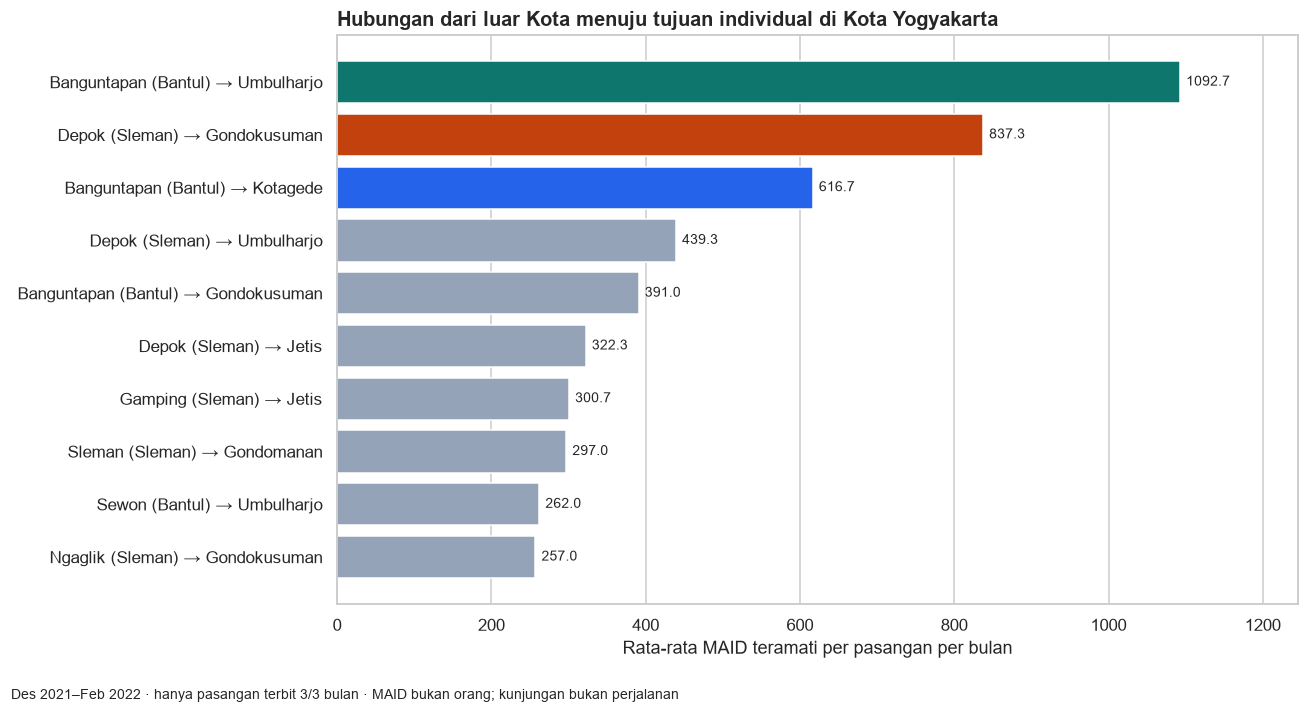

In [6]:
top = complete.head(TOP_K)
display(top[['pair_label', 'months_published', 'mean_devices_per_month', 'pooled_visit_rate']]
        .rename(columns={'pair_label': 'Pasangan', 'months_published': 'Bulan terbit',
                         'mean_devices_per_month': 'Mean MAID/bulan', 'pooled_visit_rate': 'Rate berbobot 3 bulan'})
        .style.format({'Mean MAID/bulan': '{:,.1f}', 'Rate berbobot 3 bulan': '{:.1%}'}))
fig, ax = plt.subplots(figsize=(12, 6.5))
plot = top.iloc[::-1]
bar_colors = [COLORS[list(top.index).index(i)] if list(top.index).index(i) < 3 else '#94A3B8' for i in plot.index]
bars = ax.barh(plot.pair_label, plot.mean_devices_per_month, color=bar_colors)
ax.bar_label(bars, fmt='%.1f', padding=4, fontsize=9)
ax.set_xlim(0, top.mean_devices_per_month.max() * 1.14)
ax.set_xlabel('Rata-rata MAID teramati per pasangan per bulan')
ax.set_title('Hubungan dari luar Kota menuju tujuan individual di Kota Yogyakarta', loc='left')
ax.grid(axis='y', visible=False)
fig.text(.01, .01, 'Des 2021–Feb 2022 · hanya pasangan terbit 3/3 bulan · MAID bukan orang; kunjungan bukan perjalanan', fontsize=9)
fig.tight_layout(rect=(0, .04, 1, 1))
save(fig, 'top_pairs')
plt.show()

### 3. Apakah rate pasangan utama konsisten antarbulan?

Pakai tiga pasangan teratas menurut volume rata-rata, lalu tampilkan rate setiap bulan. Range antarbulan di sini adalah variasi yang teramati, **bukan interval kepercayaan**. Perubahan panel dapat tetap memengaruhi rate.

month,2021-12,2022-01,2022-02
pair_label,,,
Banguntapan (Bantul) → Kotagede,11.4%,12.7%,10.5%
Banguntapan (Bantul) → Umbulharjo,20.3%,23.5%,17.1%
Depok (Sleman) → Gondokusuman,8.2%,10.7%,11.7%


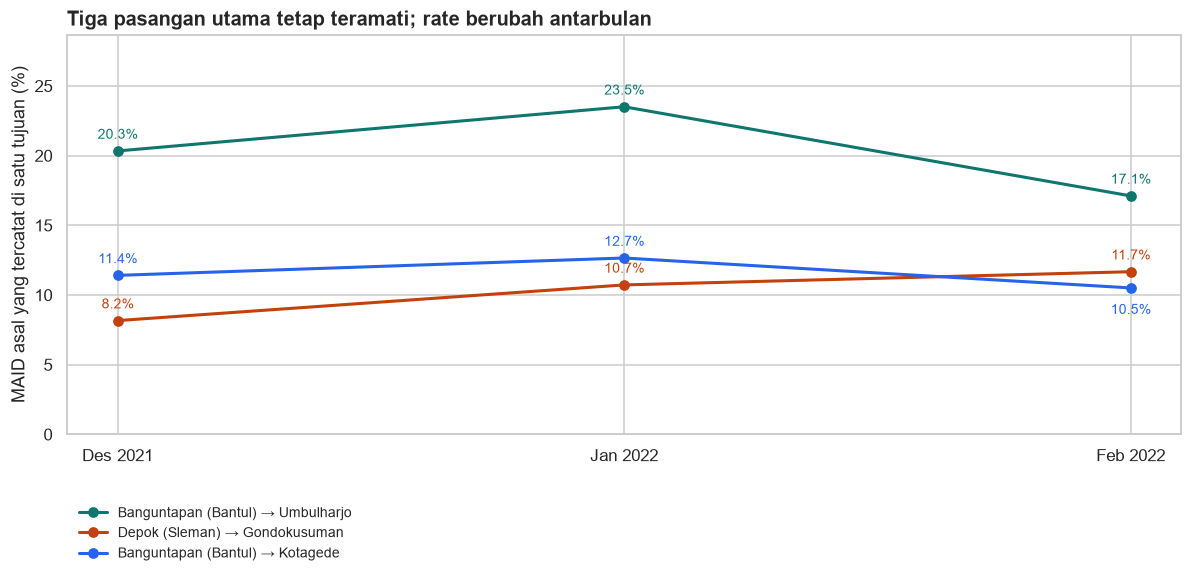

In [7]:
selected = top.head(3)[['origin_code', 'dest_code', 'pair_label']]
rates = pair_month.merge(selected, on=['origin_code', 'dest_code'], how='inner', validate='many_to_one')
rate_table = rates.pivot(index='pair_label', columns='month', values='visit_rate').reindex(columns=OD_GOOD_MONTHS)
display(rate_table.style.format('{:.1%}'))
fig, ax = plt.subplots(figsize=(11, 5.5))
for color, row in zip(COLORS, selected.itertuples()):
    curve = rates[rates.origin_code.eq(row.origin_code) & rates.dest_code.eq(row.dest_code)].set_index('month').reindex(OD_GOOD_MONTHS)
    ax.plot(range(3), curve.visit_rate.astype(float) * 100, marker='o', lw=2, color=color, label=row.pair_label)
    for i, v in enumerate(curve.visit_rate):
        offset = -17 if (i == 2 and row.dest_code == '34.71.14') else 8
        ax.annotate(f'{v:.1%}', (i, float(v) * 100), xytext=(0, offset), textcoords='offset points', ha='center', fontsize=9, color=color)
ax.set_xticks(range(3), MONTH_LABELS)
ax.set_ylim(0, float(rates.visit_rate.max()) * 100 * 1.22)
ax.set_ylabel('MAID asal yang tercatat di satu tujuan (%)')
ax.set_title('Tiga pasangan utama tetap teramati; rate berubah antarbulan', loc='left')
ax.legend(loc='upper left', bbox_to_anchor=(0, -.15), frameon=False, fontsize=9)
fig.tight_layout()
save(fig, 'monthly_rates')
plt.show()

### 4. Volume besar dan rate tinggi menjawab pertanyaan berbeda

Pilih satu tujuan. Kedua panel menampilkan **asal yang sama dalam urutan sama**: kiri jumlah perangkat per bulan; kanan pooled visit rate. Denominator setiap asal berbeda dan ditampilkan pada tabel. Pemilihan kode tujuan dapat diubah di sel setup.

,origin_kapanewon,origin_kab_kota,observed_device_months,origin_device_months,pooled_visit_rate
0,BANGUNTAPAN,BANTUL,3278,16001,20.5%
3,DEPOK,SLEMAN,1318,25048,5.3%
8,SEWON,BANTUL,786,7713,10.2%
10,GAMPING,SLEMAN,756,16964,4.5%
19,KASIHAN,BANTUL,595,16420,3.6%
38,NGAGLIK,SLEMAN,383,18798,2.0%
51,BERBAH,SLEMAN,304,3259,9.3%
65,MLATI,SLEMAN,270,9702,2.8%


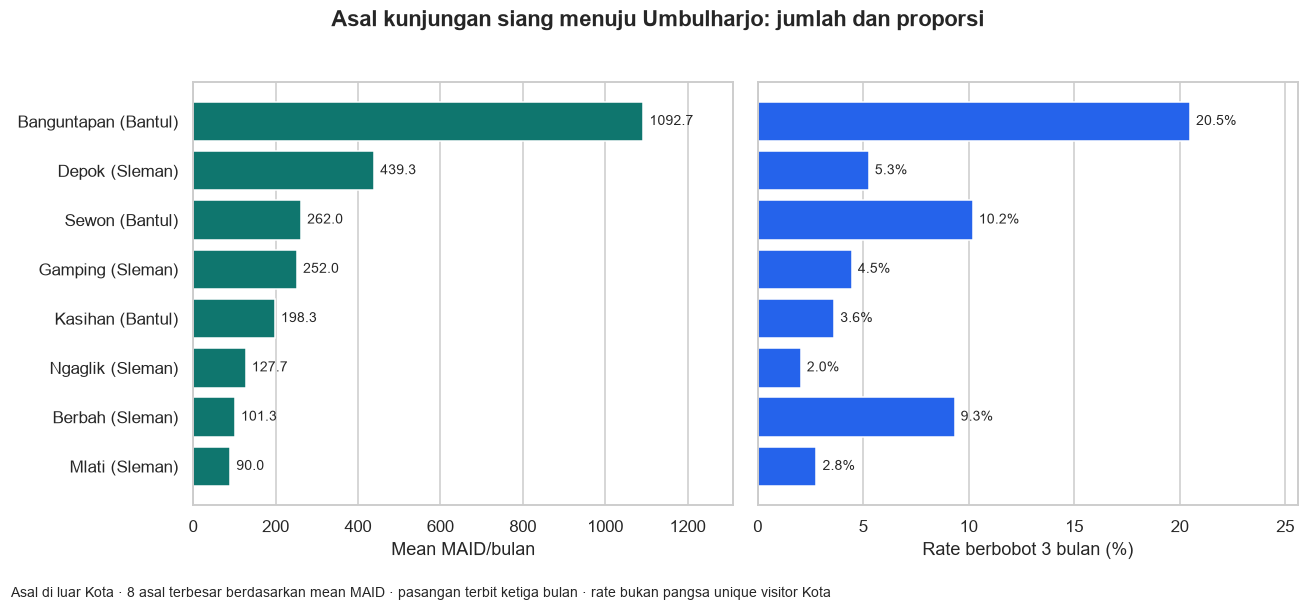

In [8]:
destination = complete[complete.dest_code.eq(DESTINATION_CODE)].head(8).copy()
assert not destination.empty, 'Tujuan tidak memiliki pasangan lengkap; pilih kode lain.'
dest_name = destination.dest_kapanewon.iloc[0].title()
display(destination[['origin_kapanewon', 'origin_kab_kota', 'observed_device_months', 'origin_device_months', 'pooled_visit_rate']]
        .style.format({'pooled_visit_rate': '{:.1%}'}))
p = destination.iloc[::-1]
labels = p.origin_kapanewon.str.title() + ' (' + p.origin_kab_kota.str.title() + ')'
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
a = axes[0].barh(labels, p.mean_devices_per_month, color='#0F766E')
axes[0].bar_label(a, fmt='%.1f', padding=4, fontsize=9)
axes[0].set_xlabel('Mean MAID/bulan')
axes[0].set_xlim(0, p.mean_devices_per_month.max() * 1.2)
b = axes[1].barh(labels, p.pooled_visit_rate.astype(float) * 100, color='#2563EB')
axes[1].bar_label(b, labels=[f'{v:.1%}' for v in p.pooled_visit_rate], padding=4, fontsize=9)
axes[1].set_xlabel('Rate berbobot 3 bulan (%)')
axes[1].set_xlim(0, float(p.pooled_visit_rate.max()) * 100 * 1.25)
for ax in axes: ax.grid(axis='y', visible=False)
fig.suptitle(f'Asal kunjungan siang menuju {dest_name}: jumlah dan proporsi', weight='bold')
fig.text(.01, .01, 'Asal di luar Kota · 8 asal terbesar berdasarkan mean MAID · pasangan terbit ketiga bulan · rate bukan pangsa unique visitor Kota', fontsize=9)
fig.tight_layout(rect=(0, .04, 1, .96))
save(fig, 'destination_origins')
plt.show()

### 5. Telusuri satu angka hingga denominatornya

Contoh Desember untuk Banguntapan→Umbulharjo. Pemeriksaan ini membantu memastikan numerator dan denominator berasal dari asal dan bulan yang sama.

In [9]:
example = pair_month.loc[pair_month.month.eq('2021-12') & pair_month.origin_code.eq('34.02.12')
                         & pair_month.dest_code.eq('34.71.13')].iloc[0]
manual_rate = int(example.n_maids) / int(example.n_homed_maids)
assert np.isclose(manual_rate, example.visit_rate)
display(Markdown(f'**{int(example.n_maids):,} / {int(example.n_homed_maids):,} = {manual_rate:.2%}**. '
                 'Artinya MAID rumah Banguntapan yang tercatat setidaknya sekali di Umbulharjo pada siang hari bulan itu.'))

**1,394 / 6,856 = 20.33%**. Artinya MAID rumah Banguntapan yang tercatat setidaknya sekali di Umbulharjo pada siang hari bulan itu.

### Reproduksi

Jalankan pipeline di README, lalu notebook dari atas ke bawah. Notebook
memeriksa 12 hitungan pasangan-bulan dan pembaginya langsung ke CSV mentah,
menghitung ulang proporsi tiga bulan, serta menguji urutan tujuan setiap bulan.
Pemeriksaan data sintetis yang sudah tersedia:
`python -m unittest discover -s tests -v`.

Bukti yang disimpan: `reports/tables/rq4_daytime_story_evidence.csv`,
`reports/tables/rq4_top_pairs.csv`, dan empat grafik `reports/figures/rq4_*.png`.
Satu grafik merupakan cerita utama; tiga lainnya lampiran.